# Notebook 02: Data Preprocessing

## Objectives

In this notebook we will:

- Prepare MRI images for Deep Learning
- Resize all images
- Normalize pixel values
- Apply data augmentation
- Create TensorFlow datasets
- Generate train, validation and test datasets

In [1]:
# ==========================================================
# Import Required Libraries
# ==========================================================

from pathlib import Path
import tensorflow as tf
import matplotlib.pyplot as plt

AUTOTUNE = tf.data.AUTOTUNE

print("TensorFlow Version :", tf.__version__)

TensorFlow Version : 2.21.0


In [2]:
# ==========================================================
# Dataset Configuration
# ==========================================================

PROJECT_ROOT = Path.cwd().parent

DATASET_PATH = PROJECT_ROOT / "data" / "raw" / "Brain_Tumor_MRI_Dataset"

TRAIN_DIR = DATASET_PATH / "Training"

TEST_DIR = DATASET_PATH / "Testing"

IMAGE_SIZE = (224,224)

BATCH_SIZE = 32

SEED = 42

In [3]:
# ==========================================================
# Create Training Dataset
# ==========================================================

train_dataset = tf.keras.utils.image_dataset_from_directory(

    TRAIN_DIR,

    validation_split=0.2,

    subset="training",

    seed=SEED,

    image_size=IMAGE_SIZE,

    batch_size=BATCH_SIZE

)

Found 2870 files belonging to 4 classes.
Using 2296 files for training.


In [4]:
# ==========================================================
# Create Testing Dataset
# ==========================================================

test_dataset = tf.keras.utils.image_dataset_from_directory(

    TEST_DIR,

    shuffle=False,

    image_size=IMAGE_SIZE,

    batch_size=BATCH_SIZE

)

Found 394 files belonging to 4 classes.


In [5]:
# ==========================================================
# Create Validation Dataset
# ==========================================================

validation_dataset = tf.keras.utils.image_dataset_from_directory(

    TRAIN_DIR,

    validation_split=0.2,

    subset="validation",

    seed=SEED,

    image_size=IMAGE_SIZE,

    batch_size=BATCH_SIZE

)

Found 2870 files belonging to 4 classes.
Using 574 files for validation.


In [6]:
print("Class Names")

print(train_dataset.class_names)

Class Names
['glioma_tumor', 'meningioma_tumor', 'no_tumor', 'pituitary_tumor']


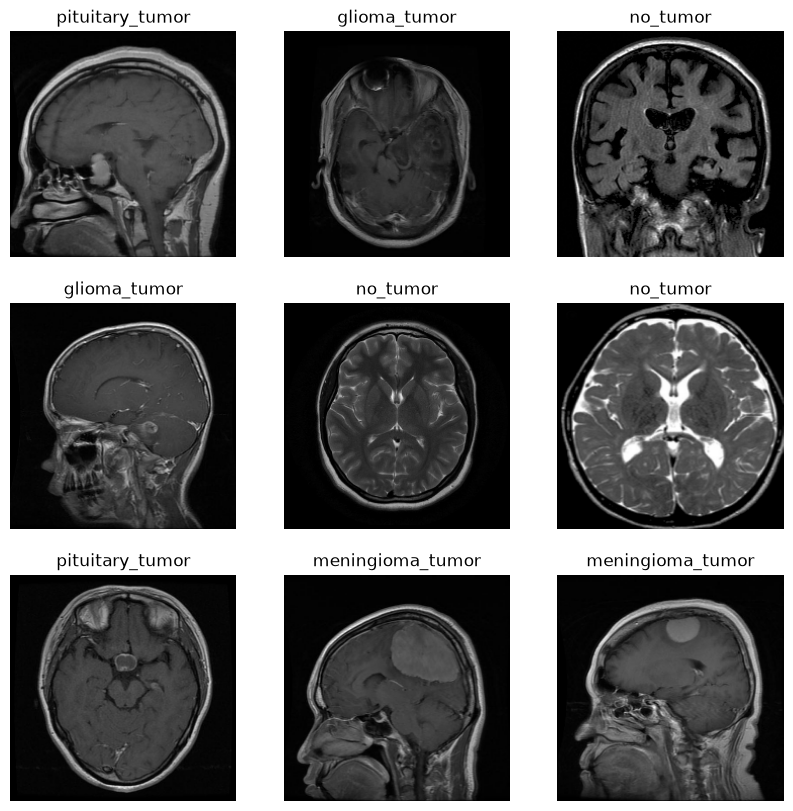

In [7]:
plt.figure(figsize=(10,10))

for images, labels in train_dataset.take(1):

    for i in range(9):

        ax = plt.subplot(3,3,i+1)

        plt.imshow(images[i].numpy().astype("uint8"))

        plt.title(train_dataset.class_names[labels[i]])

        plt.axis("off")

In [8]:
# ==========================================================
# Data Augmentation
# ==========================================================

data_augmentation = tf.keras.Sequential([

    tf.keras.layers.RandomFlip("horizontal"),

    tf.keras.layers.RandomRotation(0.10),

    tf.keras.layers.RandomZoom(0.10),

    tf.keras.layers.RandomContrast(0.10)

])

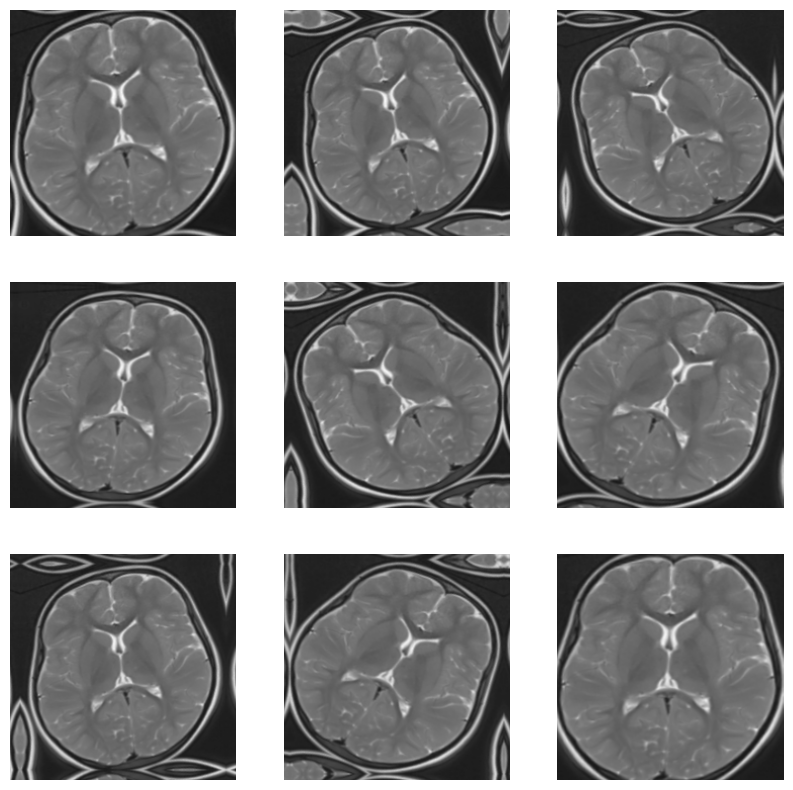

In [9]:
plt.figure(figsize=(10,10))

for images, labels in train_dataset.take(1):

    first_image = images[0]

    for i in range(9):

        ax = plt.subplot(3,3,i+1)

        augmented = data_augmentation(tf.expand_dims(first_image,0))

        plt.imshow(augmented[0].numpy().astype("uint8"))

        plt.axis("off")

In [10]:
normalization_layer = tf.keras.layers.Rescaling(1./255)

In [11]:
train_dataset = train_dataset.map(
    lambda x, y: (normalization_layer(x), y),
    num_parallel_calls=AUTOTUNE
)

validation_dataset = validation_dataset.map(
    lambda x, y: (normalization_layer(x), y),
    num_parallel_calls=AUTOTUNE
)

test_dataset = test_dataset.map(
    lambda x, y: (normalization_layer(x), y),
    num_parallel_calls=AUTOTUNE
)

In [12]:
train_dataset = train_dataset.cache().prefetch(AUTOTUNE)

validation_dataset = validation_dataset.cache().prefetch(AUTOTUNE)

test_dataset = test_dataset.prefetch(AUTOTUNE)

# Conclusion

The MRI dataset has been successfully preprocessed.

Completed Tasks:

- Dataset Loaded
- Images Resized to 224×224
- Data Augmentation Applied
- Pixel Values Normalized
- TensorFlow Dataset Pipeline Created

The dataset is now ready for CNN model training.